# Classical Machine Learning for Greek Real Estate Price Prediction

## Project Overview

This notebook investigates classical machine learning approaches for predicting residential real estate transaction prices in Greece. It builds on the datasets prepared in the two preceding notebooks: `01_data_preparation.ipynb` and `02_descriptive_analysis.ipynb`.

The objective is to experiment with regression models, understand how they work from the ground up, and compare their predictive performance using a consistent evaluation framework. Particular emphasis is placed on relative prediction error, while absolute error, root mean squared error, and the coefficient of determination are also considered to provide a broader assessment of model performance.

The notebook documents the modeling decisions, experiments, results, and limitations encountered throughout the process. It aims to combine practical model development with an understanding of the assumptions, behavior, and trade-offs associated with each approach.

## Models and Evaluation

The analysis covers several regression model families, including linear and polynomial regression, Support Vector Regression (SVR), K-Nearest Neighbors (KNN), Random Forest, Gradient Boosting, and XGBoost.

Models are evaluated using a consistent data-splitting and validation protocol to support meaningful comparisons. Hyperparameter tuning is conducted selectively, balancing potential improvements in predictive performance against computational cost.

The results are intended to provide a transparent and reproducible comparison of modeling approaches. The goal is to identify promising, practically useful models rather than to claim that exhaustive optimization or a globally optimal solution has been achieved.

## 1. Load the Modeling Dataset

Before training any models, the dataset is loaded and checked for its dimensions, missing values, duplicate rows, and column data types.

*The full cleaned dataset has zero exact duplicate rows, but selecting only the 13 modeling columns produces 21 duplicate rows. Some records differed in columns that were excluded from the modeling dataset, so they become identical after those columns are removed.*

In [39]:
from pathlib import Path

import numpy as np
import pandas as pd

DATA_PATH = Path("../data/modeling_data.parquet")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}. "
        "Check the notebook location and dataset path."
    )

modeling_df = pd.read_parquet(DATA_PATH)

print(f"Dataset shape: {modeling_df.shape}")
print(f"Missing values: {modeling_df.isna().sum().sum()}")
print(f"Exact duplicate rows: {modeling_df.duplicated().sum()}")

assert modeling_df.shape == (86085, 13)
assert modeling_df.isna().sum().sum() == 0

Dataset shape: (86085, 13)
Missing values: 0
Exact duplicate rows: 21


## 2. Define the Prediction Target and Features

The objective is to predict the recorded transaction price of a residential property using its available characteristics and the intended transaction period.

The target variable is `transaction_price_eur`. The predictors describe property size, location-related valuation information, construction year, floor, property type, and transaction timing.

The feature set also excludes `price_per_m2_eur`, because it is derived directly from the transaction price and would introduce target leakage. The original `property_type` and `apaa_status` columns are represented by their binary counterparts to avoid redundant representations.

### 2.1 Evaluating the Contribution of Municipality

The `municipal_district` feature has high cardinality and therefore requires an appropriate encoding strategy. Its contribution is evaluated by comparing two linear regression models: one using the initial numerical and binary features, and another using the same features together with the encoded municipal district.

Both models will be trained and evaluated using the same train/test split and evaluation metrics. This comparison will help determine whether the additional geographic information provides a meaningful improvement in predictive performance relative to the extra model complexity.

In [40]:

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    median_absolute_error,
    r2_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

target_column = "transaction_price_eur"

base_feature_columns = [
    "number_of_facades",
    "zone_price_eur_per_m2",
    "main_area_m2",
    "auxiliary_area_m2",
    "construction_year",
    "floor",
    "objective_value_proxy",
    "is_apartment",
    "within_appa",
    "contract_year",
    "contract_month",
]

# Use one shared split to make the comparison fair.
train_df, test_df = train_test_split(
    modeling_df,
    test_size=0.2,
    random_state=42,
)

y_train = train_df[target_column]
y_test = test_df[target_column]

# Model A: without municipal_district.
X_train_base = train_df[base_feature_columns]
X_test_base = test_df[base_feature_columns]

model_without_district = Pipeline([
    ("regressor", LinearRegression())
])

model_without_district.fit(X_train_base, y_train)
pred_without_district = model_without_district.predict(X_test_base)

# Model B: with one-hot-encoded municipal_district.
numeric_transformer = ColumnTransformer(
    transformers=[
        (
            "district",
            OneHotEncoder(handle_unknown="ignore"),
            ["municipal_district"],
        ),
        ("numeric", "passthrough", base_feature_columns),
    ],
    remainder="drop",
)

model_with_district = Pipeline([
    ("preprocessor", numeric_transformer),
    ("regressor", LinearRegression()),
])

X_train_with_district = train_df[
    ["municipal_district"] + base_feature_columns
]
X_test_with_district = test_df[
    ["municipal_district"] + base_feature_columns
]

model_with_district.fit(X_train_with_district, y_train)
pred_with_district = model_with_district.predict(X_test_with_district)


def evaluate_regression(y_true, y_pred):
    return {
        "MAE (€)": mean_absolute_error(y_true, y_pred),
        "RMSE (€)": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAPE (%)": 100 * mean_absolute_percentage_error(y_true, y_pred),
        "MdAPE (%)": 100 * np.median(
            np.abs((y_true.to_numpy() - y_pred) / y_true.to_numpy())
        ),
        "R²": r2_score(y_true, y_pred),
    }


results = pd.DataFrame(
    {
        "Without municipal_district": evaluate_regression(
            y_test, pred_without_district
        ),
        "With municipal_district": evaluate_regression(
            y_test, pred_with_district
        ),
    }
)

display(results.round(4))

,Without municipal_district,With municipal_district
MAE (€),53132.5832,54034.7286
RMSE (€),472497.4330,472674.9355
MAPE (%),43.8298,41.7753
MdAPE (%),29.2529,33.3565
R²,0.0884,0.0878


The comparison shows no consistent improvement in predictive performance when `municipal_district` is included. Although MAPE improved slightly, the overall results did not justify the additional features introduced by encoding this high-cardinality variable. Therefore, `municipal_district` is excluded from the main feature set, while its potential value in more specialized modeling approaches remains open for future investigation.

## 3. Defining the Modeling Population

Transaction prices in the prepared dataset are strongly right-skewed, with a small number of exceptionally high-value transactions. These observations can have a disproportionate influence on model fitting and evaluation, particularly for regression models trained using squared-error objectives.

To investigate the effect of the upper tail, initial experiments compared models trained on the full transaction population with models trained on a restricted population that excludes observations above the 99th percentile (P99) of transaction price. The restricted population retains 99% of transactions and focuses subsequent model development on the main body of the observed price distribution.

Excluding the upper tail is a modeling decision rather than a claim that these transactions are invalid or unimportant. The full population was also retained for experiments investigating whether alternative modeling approaches could reduce the influence of exceptionally large prediction errors. In particular, experiments using absolute-error objectives improved several evaluation metrics when models were trained on the full population. These findings suggest that alternative loss criteria may help incorporate high-value transactions without allowing a small number of large residuals to dominate model fitting. However, the results did not establish that full-population modeling consistently outperformed models trained on the P99 population across all evaluation metrics.

For the remaining model-development experiments, the P99 population is therefore adopted as the primary modeling population. This provides a consistent basis for comparing model families and conducting hyperparameter optimization. Predictions for exceptionally high-value properties remain an important limitation of the resulting models and a potential direction for further work.

Ideally, a more comprehensive prediction system could use a two-stage approach. First, a classifier would estimate whether a property is likely to belong to the upper-price segment using information available before its transaction price is known. A separate regression model could then be selected according to the predicted segment. Such a system would require its own design and evaluation, including assessment of classification errors and the consequences of routing properties to the wrong regression model.

This approach is beyond the scope of the current notebook, which focuses on developing and comparing regression models for the P99 population.

In [41]:

target_column = "transaction_price_eur"

# Calculate the 99th-percentile cutoff on the full dataset.
p99_cutoff = modeling_df[target_column].quantile(0.99)

# Retain observations at or below the cutoff.
modeling_df_p99 = modeling_df[
    modeling_df[target_column] <= p99_cutoff
].copy()

n_full = len(modeling_df)
n_p99 = len(modeling_df_p99)
n_excluded = n_full - n_p99

population_summary = pd.DataFrame(
    {
        "Full population": [
            n_full,
            modeling_df[target_column].min(),
            modeling_df[target_column].median(),
            modeling_df[target_column].max(),
        ],
        "P99 population": [
            n_p99,
            modeling_df_p99[target_column].min(),
            modeling_df_p99[target_column].median(),
            modeling_df_p99[target_column].max(),
        ],
    },
    index=[
        "Number of observations",
        "Minimum transaction price (€)",
        "Median transaction price (€)",
        "Maximum transaction price (€)",
    ],
)

print(f"P99 transaction-price cutoff: €{p99_cutoff:,.2f}")
print(f"Excluded observations: {n_excluded:,} ({n_excluded / n_full:.2%})")

display(population_summary)

P99 transaction-price cutoff: €725,532.81
Excluded observations: 861 (1.00%)


,Full population,P99 population
Number of observations,86085.00,85224.00
Minimum transaction price (€),4357.78,4357.78
Median transaction price (€),85000.00,83350.00
Maximum transaction price (€),46000000.00,725310.60


In [42]:

from sklearn.model_selection import train_test_split

target_column = "transaction_price_eur"

# Split the full population once.
train_df_full, test_df_full = train_test_split(
    modeling_df,
    test_size=0.2,
    random_state=42,
)

# Restrict the training population using the cutoff from the full dataset.
train_df_p99 = train_df_full[
    train_df_full[target_column] <= p99_cutoff
].copy()

# Use the same in-range test observations to evaluate both models.
test_df_common = test_df_full[
    test_df_full[target_column] <= p99_cutoff
].copy()

split_summary = pd.DataFrame(
    {
        "Full training population": [
            len(train_df_full),
            train_df_full[target_column].max(),
        ],
        "P99 training population": [
            len(train_df_p99),
            train_df_p99[target_column].max(),
        ],
        "Common test population": [
            len(test_df_common),
            test_df_common[target_column].max(),
        ],
    },
    index=[
        "Number of observations",
        "Maximum transaction price (€)",
    ],
)

display(split_summary)

,Full training population,P99 training population,Common test population
Number of observations,68868.0,68177.0,17047.0
Maximum transaction price (€),28000000.0,725000.0,725310.6


In [43]:

from sklearn.linear_model import LinearRegression

base_feature_columns = [
    "number_of_facades",
    "zone_price_eur_per_m2",
    "main_area_m2",
    "auxiliary_area_m2",
    "construction_year",
    "floor",
    "objective_value_proxy",
    "is_apartment",
    "within_appa",
    "contract_year",
    "contract_month",
]

X_train_full = train_df_full[base_feature_columns]
y_train_full = train_df_full[target_column]

X_train_p99 = train_df_p99[base_feature_columns]
y_train_p99 = train_df_p99[target_column]

X_test_common = test_df_common[base_feature_columns]
y_test_common = test_df_common[target_column]

linear_full = LinearRegression()
linear_full.fit(X_train_full, y_train_full)
pred_linear_full = linear_full.predict(X_test_common)

linear_p99 = LinearRegression()
linear_p99.fit(X_train_p99, y_train_p99)
pred_linear_p99 = linear_p99.predict(X_test_common)

linear_population_results = pd.DataFrame(
    {
        "Trained on full population": evaluate_regression(
            y_test_common, pred_linear_full
        ),
        "Trained on P99 population": evaluate_regression(
            y_test_common, pred_linear_p99
        ),
    }
)

display(linear_population_results.round(4))


,Trained on full population,Trained on P99 population
MAE (€),38920.3379,34429.7525
RMSE (€),63037.8226,54082.2926
MAPE (%),43.7385,36.9959
MdAPE (%),29.1005,27.7614
R²,0.5207,0.6472


The linear regression comparison shows consistently better predictive performance when the model is trained on the P99 population rather than the full population. Evaluated on the same test observations, the P99 model achieved lower MAE, RMSE, MAPE, and MdAPE, while its R² increased from 0.521 to 0.647.

Considering that the excluded observations represent only 1% of the full dataset, and that their inclusion resulted in poorer predictive performance across all five evaluation metrics, it was decided to exclude them from the main modeling population.

The decision will also be evaluated using Random Forest to determine whether the improvement extends beyond linear regression.

In [44]:

from sklearn.ensemble import RandomForestRegressor

rf_params = {
    "n_estimators": 200,
    "max_depth": 10,
    "max_features": 0.6,
    "random_state": 42,
    "n_jobs": -1,
}

# Train on the full population.
rf_full = RandomForestRegressor(**rf_params)
rf_full.fit(X_train_full, y_train_full)

pred_rf_full = rf_full.predict(X_test_common)

# Train on the P99 population.
rf_p99 = RandomForestRegressor(**rf_params)
rf_p99.fit(X_train_p99, y_train_p99)

pred_rf_p99 = rf_p99.predict(X_test_common)

# Evaluate both models on the same test observations.
rf_population_results = pd.DataFrame(
    {
        "Trained on full population": evaluate_regression(
            y_test_common, pred_rf_full
        ),
        "Trained on P99 population": evaluate_regression(
            y_test_common, pred_rf_p99
        ),
    }
)

display(rf_population_results.round(4))

,Trained on full population,Trained on P99 population
MAE (€),38816.3807,32931.1359
RMSE (€),75318.7041,51872.5102
MAPE (%),42.1529,34.4929
MdAPE (%),31.5042,27.4048
R²,0.3157,0.6754


The Random Forest comparison confirms the pattern observed with Linear Regression. When evaluated on the same test observations, the model trained on the P99 population achieved lower MAE, RMSE, MAPE, and MdAPE, while its R² increased from 0.316 to 0.675.

The improvement was particularly pronounced in RMSE, which decreased by approximately 31%, suggesting that the extreme upper tail in the training data had a substantial effect on the model's predictions for the main price range. The consistency of the results across two different model families supports the decision to exclude the top 1% of transaction prices from the main modeling population.

This conclusion is specific to predicting transactions within the retained price range. Since the common test set excludes transactions above the P99 cutoff, these experiments do not establish how well either model predicts exceptionally high-value transactions.

In [45]:

baseline_results = pd.DataFrame(
    {
        "Linear Regression — Full": evaluate_regression(
            y_test_common, pred_linear_full
        ),
        "Linear Regression — P99": evaluate_regression(
            y_test_common, pred_linear_p99
        ),
        "Random Forest — Full": evaluate_regression(
            y_test_common, pred_rf_full
        ),
        "Random Forest — P99": evaluate_regression(
            y_test_common, pred_rf_p99
        ),
    }
).T

display(baseline_results.round(4))


,MAE (€),RMSE (€),MAPE (%),MdAPE (%),R²
Linear Regression — Full,38920.3379,63037.8226,43.7385,29.1005,0.5207
Linear Regression — P99,34429.7525,54082.2926,36.9959,27.7614,0.6472
Random Forest — Full,38816.3807,75318.7041,42.1529,31.5042,0.3157
Random Forest — P99,32931.1359,51872.5102,34.4929,27.4048,0.6754


### Regression with an Absolute-Error Loss Function

The earlier experiments showed that training on the full transaction population produced weaker results than restricting the training data to the 99th percentile of transaction price. This raised the question of whether a different loss function could reduce the influence of exceptionally large prediction errors while retaining the full population.

Unlike squared-error loss, which squares residuals and therefore places a disproportionate penalty on large errors, absolute-error loss penalizes residuals in direct proportion to their magnitude. A model trained with this objective may therefore be less sensitive to extreme observations.

An absolute-error regression experiment was conducted to investigate whether this alternative objective could improve predictive performance when using the full population. Its results are compared with the existing baselines to assess whether changing the loss function offers a practical alternative to excluding the upper tail.

This experiment does not assume that high-value transactions are invalid or that absolute-error loss eliminates their influence. Its purpose is to evaluate the trade-off empirically.

In [46]:
from sklearn.linear_model import QuantileRegressor

absolute_error_model = QuantileRegressor(
    quantile=0.5,
    alpha=0,
    solver="highs",
)

absolute_error_model.fit(
    X_train_full,
    y_train_full,
)

pred_absolute_error_full = absolute_error_model.predict(
    X_test_common
)

print("Model fitted successfully.")
print(f"Training observations: {len(X_train_full):,}")
print(f"Test observations: {len(X_test_common):,}")

Model fitted successfully.
Training observations: 68,868
Test observations: 17,047


In [47]:
absolute_error_results = pd.Series(
    evaluate_regression(
        y_test_common,
        pred_absolute_error_full,
    ),
    name="Quantile Regression — Full Population",
)

display(absolute_error_results.to_frame().round(4))

,Quantile Regression — Full Population
MAE (€),32908.6519
RMSE (€),55763.3723
MAPE (%),30.0949
MdAPE (%),24.5607
R²,0.6249


The model was configured with `quantile=0.5` and `alpha=0`, corresponding to median regression without regularization.

On the common test set, Quantile Regression achieved an MAE of approximately €32,909, outperforming both ordinary Linear Regression and Random Forest trained on the full population. It also achieved lower MAE than the P99-trained Random Forest, although the difference was small.

However, its RMSE and R² remained weaker than those of the P99-trained Random Forest.

The results suggest that absolute-error optimization is a promising alternative to excluding the upper tail of the training distribution. Nevertheless, it does not eliminate the influence of extreme transactions, and its performance should be assessed across multiple metrics rather than MAE alone.

### Random Forest with Absolute-Error Criterion

The previous experiment showed that Quantile Regression, which minimizes absolute errors at the median, improved MAE when trained on the full transaction population. This raises the question of whether a similar benefit can be achieved with a nonlinear model.

Random Forest Regression is therefore evaluated using the `absolute_error` criterion instead of the default `squared_error` criterion. The model is trained on the full population and evaluated on the same common test set, allowing its performance to be compared with the existing baselines.

Because absolute-error splitting is more computationally expensive, training time may increase. The purpose of this experiment is to assess whether changing the criterion improves predictive performance without excluding high-value transactions.

In [48]:
from sklearn.ensemble import RandomForestRegressor

rf_absolute_error_params = {
    "n_estimators": 200,
    "max_depth": 10,
    "max_features": 0.6,
    "criterion": "absolute_error",
    "random_state": 42,
    "n_jobs": -1,
}

rf_absolute_error_full = RandomForestRegressor(
    **rf_absolute_error_params
)

rf_absolute_error_full.fit(
    X_train_full,
    y_train_full,
)

pred_rf_absolute_error_full = (
    rf_absolute_error_full.predict(X_test_common)
)

print("Random Forest with absolute-error criterion fitted successfully.")

Random Forest with absolute-error criterion fitted successfully.


In [49]:
rf_absolute_error_results = pd.Series(
    evaluate_regression(
        y_test_common,
        pred_rf_absolute_error_full,
    ),
    name="Random Forest — Absolute Error (Full)",
)

display(rf_absolute_error_results.to_frame().round(4))

,Random Forest — Absolute Error (Full)
MAE (€),32523.1862
RMSE (€),58273.2603
MAPE (%),28.7684
MdAPE (%),23.3272
R²,0.5904


In [50]:
absolute_error_comparison = pd.DataFrame(
    {
        "Linear Regression — Full": evaluate_regression(
            y_test_common, pred_linear_full
        ),
        "Random Forest — Full (Squared Error)": evaluate_regression(
            y_test_common, pred_rf_full
        ),
        "Quantile Regression — Full": evaluate_regression(
            y_test_common, pred_absolute_error_full
        ),
        "Random Forest — Full (Absolute Error)": evaluate_regression(
            y_test_common, pred_rf_absolute_error_full
        ),
        "Linear Regression — P99": evaluate_regression(
            y_test_common, pred_linear_p99
        ),
        "Random Forest — P99": evaluate_regression(
            y_test_common, pred_rf_p99
        ),
    }
).T

display(absolute_error_comparison.round(4))

,MAE (€),RMSE (€),MAPE (%),MdAPE (%),R²
Linear Regression — Full,38920.3379,63037.8226,43.7385,29.1005,0.5207
Random Forest — Full (Squared Error),38816.3807,75318.7041,42.1529,31.5042,0.3157
Quantile Regression — Full,32908.6519,55763.3723,30.0949,24.5607,0.6249
Random Forest — Full (Absolute Error),32523.1862,58273.2603,28.7684,23.3272,0.5904
Linear Regression — P99,34429.7525,54082.2926,36.9959,27.7614,0.6472
Random Forest — P99,32931.1359,51872.5102,34.4929,27.4048,0.6754


### Effect of the Absolute-Error Criterion

Using the absolute-error criterion improved all five evaluation metrics for the Random Forest trained on the full transaction population. Compared with the default squared-error criterion, MAE decreased from approximately €38,816 to €32,523 (a reduction of 16.2%), while RMSE decreased by 22.6%. MAPE, MdAPE, and R² also improved.

For this comparison, the Random Forest models used the same hyperparameters, training population, and test set; only the `criterion` was changed from `squared_error` to `absolute_error`. This provides a controlled initial comparison of the two criteria.

Hyperparameter optimization has not yet been performed for either model. The results should therefore be interpreted as evidence that the absolute-error criterion is promising under the current configuration, rather than proof that it will remain superior after tuning.

### Linear Regression with a Log-Transformed Target

Transaction prices are strongly right-skewed, so Linear Regression is also evaluated using the natural logarithm of `transaction_price_eur` as the target. This transformation may help the model capture relative differences in price and reduce the influence of large values during fitting.

Predictions are transformed back to euros before evaluation, allowing direct comparison with the original-scale model. Because exponentiation introduces retransformation bias, a smearing correction will also be applied.

In [51]:
from sklearn.linear_model import LinearRegression

# Transform the target, not the predictor features.
y_train_p99_log = np.log(y_train_p99)

# Fit Linear Regression on log-transformed transaction prices.
linear_log_p99 = LinearRegression()
linear_log_p99.fit(X_train_p99, y_train_p99_log)

# Predict on the log scale.
pred_log_p99 = linear_log_p99.predict(X_test_common)

# Convert predictions back to euros.
pred_linear_log_p99 = np.exp(pred_log_p99)

# Evaluate on the original price scale.
log_linear_results = pd.Series(
    evaluate_regression(y_test_common, pred_linear_log_p99),
    name="Log Linear Regression — P99",
)

display(log_linear_results.to_frame().round(4))

,Log Linear Regression — P99
MAE (€),43088.0012
RMSE (€),150354.9664
MAPE (%),35.5604
MdAPE (%),26.3655
R²,-1.7269


In [52]:

log_prediction_diagnostics = pd.DataFrame(
    {
        "Actual price (€)": y_test_common.to_numpy(),
        "Predicted price (€)": pred_linear_log_p99,
    }
)

log_prediction_diagnostics["Absolute error (€)"] = np.abs(
    log_prediction_diagnostics["Actual price (€)"]
    - log_prediction_diagnostics["Predicted price (€)"]
)

display(
    log_prediction_diagnostics[
        ["Actual price (€)", "Predicted price (€)", "Absolute error (€)"]
    ].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(2)
)

display(
    log_prediction_diagnostics.nlargest(10, "Absolute error (€)").round(2)
)


,Actual price (€),Predicted price (€),Absolute error (€)
count,17047.00,17047.00,17047.00
mean,111401.64,110591.37,43088.00
std,91053.75,176462.64,144052.97
min,4357.78,17224.52,0.10
50%,83600.00,79213.49,19292.77
90%,231553.07,174354.66,88329.17
95%,280000.00,249092.73,146949.88
99%,492431.50,602014.00,339897.12
max,725310.60,7828822.46,7358822.46


,Actual price (€),Predicted price (€),Absolute error (€)
10259,470000.00,7828822.46,7358822.46
2502,283955.83,7390776.23,7106820.40
12318,444361.10,4794179.32,4349818.22
5528,257467.85,4084887.21,3827419.36
6000,629299.44,4316572.22,3687272.78
11608,601383.83,4173295.19,3571911.36
14888,155000.00,3569586.63,3414586.63
13022,700000.00,3988146.38,3288146.38
2476,260302.44,3346224.44,3085922.00
16917,650000.00,3711991.02,3061991.02


In [53]:

log_scale_diagnostics = pd.DataFrame(
    {
        "Actual price (€)": y_test_common.to_numpy(),
        "Actual log-price": np.log(y_test_common.to_numpy()),
        "Predicted log-price": pred_log_p99,
        "Predicted price (€)": pred_linear_log_p99,
    }
)

display(
    log_scale_diagnostics[
        ["Actual log-price", "Predicted log-price"]
    ].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(4)
)

display(
    log_scale_diagnostics.nlargest(
        10, "Predicted log-price"
    ).round(4)
)

,Actual log-price,Predicted log-price
count,17047.0000,17047.0000
mean,11.3573,11.3638
std,0.7233,0.5860
min,8.3797,9.7541
50%,11.3338,11.2799
90%,12.3526,12.0688
95%,12.5425,12.4256
99%,13.1071,13.3080
max,13.4944,15.8733


,Actual price (€),Actual log-price,Predicted log-price,Predicted price (€)
10259,470000.00,13.0605,15.8733,7.828822e+06
2502,283955.83,12.5566,15.8157,7.390776e+06
12318,444361.10,13.0044,15.3829,4.794179e+06
6000,629299.44,13.3524,15.2780,4.316572e+06
11608,601383.83,13.3070,15.2442,4.173295e+06
5528,257467.85,12.4587,15.2228,4.084887e+06
13022,700000.00,13.4588,15.1988,3.988146e+06
16917,650000.00,13.3847,15.1271,3.711991e+06
14888,155000.00,11.9512,15.0880,3.569587e+06
485,692516.25,13.4481,15.0532,3.447530e+06


### Investigating Extreme Predictions

The diagnostic results reveal that a small number of unusually high log-price predictions become extremely large after exponentiation. Although the model achieves slightly better median and mean absolute percentage errors, these extreme overpredictions substantially increase MAE and RMSE and result in a negative R².

Duan’s smearing factor will be investigated as a correction for retransformation bias, while recognizing that it may not resolve the model’s extreme prediction errors.

In [54]:

# Predict log-prices for the P99 training observations.
pred_train_log_p99 = linear_log_p99.predict(X_train_p99)

# Calculate residuals on the log scale.
train_log_residuals = (
    y_train_p99_log.to_numpy() - pred_train_log_p99
)

# Estimate Duan's smearing factor.
smearing_factor = np.mean(np.exp(train_log_residuals))

print(f"Smearing factor: {smearing_factor:.6f}")

Smearing factor: 1.110307


In [55]:

# Apply Duan's smearing correction to the test predictions.
pred_linear_log_p99_smeared = (
    np.exp(pred_log_p99) * smearing_factor
)

# Evaluate the corrected predictions in euros.
log_linear_smeared_results = pd.Series(
    evaluate_regression(
        y_test_common,
        pred_linear_log_p99_smeared,
    ),
    name="Log Linear Regression — P99 + Smearing",
)

display(log_linear_smeared_results.to_frame().round(4))


,Log Linear Regression — P99 + Smearing
MAE (€),46001.8579
RMSE (€),167715.0169
MAPE (%),41.2906
MdAPE (%),29.7046
R²,-2.3929


### Evaluating Duan's Smearing Correction

Duan's smearing factor was estimated from the training residuals on the log scale and applied to the exponentiated test predictions. In this experiment, the correction increased MAE, RMSE, MAPE, and MdAPE, while R² decreased further. The diagnostic analysis indicates that a small number of extreme predictions dominate the squared-error performance. Therefore, the smearing correction did not improve predictive accuracy on the original price scale, and the log-linear model was not retained as the preferred baseline.

## Regularized Linear Models

Ordinary Linear Regression estimates coefficients by minimizing the sum of squared prediction errors. When predictors have different scales or are correlated with one another, the estimated coefficients can become sensitive to the training data.

Regularized linear models address this by adding a penalty to the regression objective. The penalty discourages excessively large coefficients and can help control model complexity.

This section evaluates Ridge Regression, Lasso Regression, and Elastic Net using the P99 training population and the same test set used in the previous experiments. Predictors are standardized, and regularization strength is selected through cross-validation on the training data.

The aim is to determine whether regularization improves predictive performance over the ordinary Linear Regression baseline while providing insight into how coefficient constraints affect the model.

In [56]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.model_selection import GridSearchCV

print(f"Training features: {X_train_p99.shape}")
print(f"Test features: {X_test_common.shape}")
print(f"Training target: {y_train_p99.shape}")
print(f"Test target: {y_test_common.shape}")

Training features: (68177, 11)
Test features: (17047, 11)
Training target: (68177,)
Test target: (17047,)


In [57]:
ridge_pipeline = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("model", Ridge()),
    ]
)

ridge_param_grid = {
    "model__alpha": [0.01, 0.1, 1, 10, 100, 1000],
}

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_param_grid,
    scoring="neg_mean_absolute_error",
    cv=5,
    n_jobs=-1,
    return_train_score=True,
)

ridge_search.fit(X_train_p99, y_train_p99)

print(f"Best alpha: {ridge_search.best_params_['model__alpha']}")
print(f"Best CV MAE: €{-ridge_search.best_score_:,.2f}")

Best alpha: 0.01
Best CV MAE: €34,496.31


In [58]:
ridge_p99 = ridge_search.best_estimator_

pred_ridge_p99 = ridge_p99.predict(X_test_common)

ridge_results = pd.Series(
    evaluate_regression(y_test_common, pred_ridge_p99),
    name="Ridge Regression — P99",
)

display(ridge_results.to_frame().round(4))

,Ridge Regression — P99
MAE (€),34429.7529
RMSE (€),54082.2922
MAPE (%),36.9959
MdAPE (%),27.7614
R²,0.6472


### Ridge Regression Results

Ridge Regression was evaluated using five-fold cross-validation to select the regularization strength. The best value among the tested candidates was \(\alpha = 0.01\), the smallest value in the search grid.

On the common test set, Ridge Regression produced virtually identical results to ordinary Linear Regression across all five evaluation metrics. This indicates that the selected penalty was too weak to produce a meaningful change in predictive performance.

Although Ridge did not improve the baseline, the experiment provides a useful reference point for comparing stronger regularization and methods that can reduce coefficients more selectively.

In [59]:
from sklearn.linear_model import Lasso

lasso_pipeline = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("model", Lasso(max_iter=20_000)),
    ]
)

lasso_param_grid = {
    "model__alpha": [0.01, 0.1, 1, 10, 100, 1000],
}

lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_param_grid,
    scoring="neg_mean_absolute_error",
    cv=5,
    n_jobs=-1,
    return_train_score=True,
)

lasso_search.fit(X_train_p99, y_train_p99)

print(f"Best alpha: {lasso_search.best_params_['model__alpha']}")
print(f"Best CV MAE: €{-lasso_search.best_score_:,.2f}")

Best alpha: 100
Best CV MAE: €34,493.02


In [60]:
lasso_p99 = lasso_search.best_estimator_

pred_lasso_p99 = lasso_p99.predict(X_test_common)

lasso_results = pd.Series(
    evaluate_regression(y_test_common, pred_lasso_p99),
    name="Lasso Regression — P99",
)

display(lasso_results.to_frame().round(4))

,Lasso Regression — P99
MAE (€),34426.9496
RMSE (€),54072.9066
MAPE (%),36.9907
MdAPE (%),27.8268
R²,0.6473


In [61]:
lasso_coefficients = pd.Series(
    lasso_p99.named_steps["model"].coef_,
    index=base_feature_columns,
    name="Lasso coefficient",
)

lasso_coefficient_summary = pd.DataFrame(
    {
        "Coefficient": lasso_coefficients,
        "Absolute coefficient": lasso_coefficients.abs(),
    }
).sort_values("Absolute coefficient", ascending=False)

display(lasso_coefficient_summary.round(4))

n_zero = int((lasso_coefficients == 0).sum())
n_nonzero = int((lasso_coefficients != 0).sum())

print(f"Zero coefficients: {n_zero} of {len(lasso_coefficients)}")
print(f"Non-zero coefficients: {n_nonzero} of {len(lasso_coefficients)}")

,Coefficient,Absolute coefficient
objective_value_proxy,53186.8010,53186.8010
zone_price_eur_per_m2,14501.9998,14501.9998
main_area_m2,11816.1136,11816.1136
construction_year,9657.0825,9657.0825
contract_year,9431.2066,9431.2066
within_appa,-8383.8610,8383.8610
is_apartment,-4484.7508,4484.7508
auxiliary_area_m2,4419.1427,4419.1427
floor,3870.4918,3870.4918
contract_month,1528.6576,1528.6576


Zero coefficients: 0 of 11
Non-zero coefficients: 11 of 11


### Lasso Regression Results

Lasso Regression achieved marginally lower MAE and RMSE than ordinary Linear Regression, while producing a slightly higher median absolute percentage error. Overall, the differences in predictive performance were negligible.

At the selected regularization strength of \(\alpha = 100\), all 11 predictor coefficients remained non-zero. Therefore, Lasso did not eliminate any predictors in this experiment, although it did apply coefficient shrinkage. The coefficient magnitudes should be interpreted in the context of standardized predictors and should not be treated as causal effects.

These results suggest that Lasso provides little predictive improvement over the ordinary linear baseline at the tested regularization strength.

In [62]:
from sklearn.linear_model import ElasticNet

elastic_net_pipeline = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("model", ElasticNet(max_iter=20_000)),
    ]
)

elastic_net_param_grid = {
    "model__alpha": [0.01, 0.1, 1, 10, 100, 1000],
    "model__l1_ratio": [0.1, 0.5, 0.9],
}

elastic_net_search = GridSearchCV(
    estimator=elastic_net_pipeline,
    param_grid=elastic_net_param_grid,
    scoring="neg_mean_absolute_error",
    cv=5,
    n_jobs=-1,
    return_train_score=True,
)

elastic_net_search.fit(X_train_p99, y_train_p99)

print(f"Best parameters: {elastic_net_search.best_params_}")
print(f"Best CV MAE: €{-elastic_net_search.best_score_:,.2f}")

Best parameters: {'model__alpha': 0.01, 'model__l1_ratio': 0.9}
Best CV MAE: €34,500.07


In [63]:
elastic_net_p99 = elastic_net_search.best_estimator_

pred_elastic_net_p99 = elastic_net_p99.predict(X_test_common)

elastic_net_results = pd.Series(
    evaluate_regression(y_test_common, pred_elastic_net_p99),
    name="Elastic Net — P99",
)

display(elastic_net_results.to_frame().round(4))

,Elastic Net — P99
MAE (€),34432.0390
RMSE (€),54079.6611
MAPE (%),36.9896
MdAPE (%),27.7564
R²,0.6472


In [64]:
regularized_linear_results = pd.DataFrame(
    {
        "Linear Regression — P99": evaluate_regression(
            y_test_common, pred_linear_p99
        ),
        "Ridge — P99": evaluate_regression(
            y_test_common, pred_ridge_p99
        ),
        "Lasso — P99": evaluate_regression(
            y_test_common, pred_lasso_p99
        ),
        "Elastic Net — P99": evaluate_regression(
            y_test_common, pred_elastic_net_p99
        ),
    }
).T

display(regularized_linear_results.round(4))

,MAE (€),RMSE (€),MAPE (%),MdAPE (%),R²
Linear Regression — P99,34429.7525,54082.2926,36.9959,27.7614,0.6472
Ridge — P99,34429.7529,54082.2922,36.9959,27.7614,0.6472
Lasso — P99,34426.9496,54072.9066,36.9907,27.8268,0.6473
Elastic Net — P99,34432.0390,54079.6611,36.9896,27.7564,0.6472


### Summary of Regularized Linear Models

All three models produced predictive performance very similar to ordinary Linear Regression. Lasso and Elastic Net showed small differences across individual metrics, but none delivered a substantial overall improvement. In addition, Lasso retained all 11 predictors at its selected regularization strength, so no features were eliminated.

For this dataset and feature set, regularization did not improve predictive accuracy. The experiments nevertheless provide a useful comparison of L1 and L2 penalties and establish a baseline for evaluating models capable of capturing nonlinear relationships.

## Polynomial Regression

The linear models evaluated so far assume that the relationship between each predictor and transaction price is linear, conditional on the other predictors. However, real-estate prices may respond to property characteristics in nonlinear ways. For example, the relationship between floor area and price may not be constant across property sizes.

Polynomial Regression extends a linear model by adding polynomial terms, such as squared predictors, allowing it to represent some nonlinear relationships while remaining linear in its estimated coefficients.

In this experiment, second-degree polynomial features are introduced for the existing predictors, and the resulting model is evaluated using the P99 training population and the common test set. The aim is to determine whether these additional terms improve predictive performance over the existing linear baselines.

Polynomial expansion can substantially increase the number of predictors and introduce strong correlations between them. Therefore, the experiment will use a standardized preprocessing pipeline and Ridge regularization to help control model complexity.

In [65]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

polynomial_ridge_pipeline = Pipeline(
    steps=[
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("scaler", StandardScaler()),
        ("model", Ridge()),
    ]
)

polynomial_ridge_param_grid = {
    "model__alpha": [0.1, 1, 10, 100, 1000],
}

polynomial_ridge_search = GridSearchCV(
    estimator=polynomial_ridge_pipeline,
    param_grid=polynomial_ridge_param_grid,
    scoring="neg_mean_absolute_error",
    cv=5,
    n_jobs=-1,
    return_train_score=True,
)

polynomial_ridge_search.fit(
    X_train_p99,
    y_train_p99,
)

print("Best parameters:", polynomial_ridge_search.best_params_)
print(
    f"Best cross-validation MAE: "
    f"€{-polynomial_ridge_search.best_score_:,.2f}"
)

Best parameters: {'model__alpha': 0.1}
Best cross-validation MAE: €33,195.48


In [66]:
polynomial_ridge_p99 = polynomial_ridge_search.best_estimator_

pred_polynomial_ridge_p99 = polynomial_ridge_p99.predict(
    X_test_common
)

polynomial_ridge_results = pd.Series(
    evaluate_regression(
        y_test_common,
        pred_polynomial_ridge_p99,
    ),
    name="Polynomial Ridge — P99",
)

display(polynomial_ridge_results.to_frame().round(4))

,Polynomial Ridge — P99
MAE (€),33073.3355
RMSE (€),52275.8984
MAPE (%),34.4330
MdAPE (%),26.4237
R²,0.6704


In [67]:
polynomial_feature_count = (
    polynomial_ridge_p99
    .named_steps["poly"]
    .n_output_features_
)

original_feature_count = len(base_feature_columns)

print(f"Original predictors: {original_feature_count}")
print(f"Polynomial predictors: {polynomial_feature_count}")
print(
    f"Additional predictors: "
    f"{polynomial_feature_count - original_feature_count}"
)

Original predictors: 11
Polynomial predictors: 77
Additional predictors: 66


In [68]:
linear_p99_metrics = evaluate_regression(
    y_test_common,
    pred_linear_p99,
)

polynomial_p99_metrics = evaluate_regression(
    y_test_common,
    pred_polynomial_ridge_p99,
)

polynomial_improvement = pd.DataFrame(
    {
        "Linear Regression — P99": linear_p99_metrics,
        "Polynomial Ridge — P99": polynomial_p99_metrics,
    }
)

polynomial_improvement["Relative change (%)"] = (
    (
        polynomial_improvement["Polynomial Ridge — P99"]
        - polynomial_improvement["Linear Regression — P99"]
    )
    / polynomial_improvement["Linear Regression — P99"]
    * 100
)

display(polynomial_improvement.round(4))

,Linear Regression — P99,Polynomial Ridge — P99,Relative change (%)
MAE (€),34429.7525,33073.3355,-3.9397
RMSE (€),54082.2926,52275.8984,-3.3401
MAPE (%),36.9959,34.4330,-6.9274
MdAPE (%),27.7614,26.4237,-4.8185
R²,0.6472,0.6704,3.5808


### Assessing the Benefit of Polynomial Expansion

The degree-2 Polynomial Ridge model improved all five evaluation metrics relative to ordinary Linear Regression on the P99 population. MAE decreased by 3.94%, RMSE by 3.34%, MAPE by 6.93%, and MdAPE by 4.82%, while R² increased only marginally.

These results indicate that squared terms and pairwise interactions capture some additional structure in the relationship between property characteristics and transaction prices. However, the improvement is moderate compared with the increase from 11 to 77 predictors. Ridge regularization helps control the complexity introduced by this expansion.

The results support using degree-2 Polynomial Ridge as a useful nonlinear baseline. Whether higher-degree polynomial features provide further gains remains an empirical question and should be investigated only with appropriate attention to computational cost and overfitting.

## Random Forest — Hyperparameter Optimization

The initial Random Forest experiments used manually selected hyperparameters to establish a baseline and compare training populations and splitting criteria. These experiments demonstrated the model's potential, but they did not establish whether the selected configuration was optimal.

Hyperparameter optimization systematically evaluates alternative model configurations to identify settings that improve predictive performance. In this experiment, `RandomizedSearchCV` will sample combinations of hyperparameters and evaluate them using five-fold cross-validation on the P99 training population. Mean Absolute Error (MAE) will be used as the selection metric, consistent with the evaluation approach used in the earlier linear-model experiments.

The search will investigate the number of trees, tree depth, minimum samples required for splits and leaves, the number of features considered at each split, and the splitting criterion. The existing Random Forest configuration will remain as the baseline for comparison.

The common test set will not be used during hyperparameter selection. Once the best configuration has been selected using cross-validation, the resulting model will be evaluated on the common test set to assess its generalization performance.

In [69]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

rf_param_distributions = {
    "n_estimators": randint(100, 501),
    "max_depth": [None, 10, 15, 20, 25, 30],
    "min_samples_split": randint(2, 21),
    "min_samples_leaf": randint(1, 11),
    "max_features": uniform(loc=0.3, scale=0.7),
    "criterion": ["squared_error", "absolute_error"],
} 

In [70]:
rf_random_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=-1,
    ),
    param_distributions=rf_param_distributions,
    n_iter=12,
    scoring="neg_mean_absolute_error",
    cv=3,
    random_state=42,
    n_jobs=1,
    verbose=2,
    return_train_score=True,
)

In [ ]:
rf_random_search.fit(X_train_p99, y_train_p99)

print("Best hyperparameters:")
print(rf_random_search.best_params_)

print(
    f"\nBest cross-validation MAE: "
    f"€{-rf_random_search.best_score_:,.2f}"
)

In [72]:
rf_tuned_p99 = rf_random_search.best_estimator_

pred_rf_tuned_p99 = rf_tuned_p99.predict(X_test_common)

rf_tuned_results = pd.Series(
    evaluate_regression(y_test_common, pred_rf_tuned_p99),
    name="Random Forest — Tuned P99",
)

display(rf_tuned_results.to_frame().round(4))

,Random Forest — Tuned P99
MAE (€),30965.0689
RMSE (€),52299.3273
MAPE (%),28.2876
MdAPE (%),23.0626
R²,0.6701


In [73]:
rf_baseline_metrics = evaluate_regression(
    y_test_common,
    pred_rf_p99,
)

rf_tuned_metrics = evaluate_regression(
    y_test_common,
    pred_rf_tuned_p99,
)

rf_tuning_comparison = pd.DataFrame(
    {
        "Random Forest — Baseline P99": rf_baseline_metrics,
        "Random Forest — Tuned P99": rf_tuned_metrics,
    }
)

rf_tuning_comparison["Relative change (%)"] = (
    (
        rf_tuning_comparison["Random Forest — Tuned P99"]
        - rf_tuning_comparison["Random Forest — Baseline P99"]
    )
    / rf_tuning_comparison["Random Forest — Baseline P99"]
    * 100
)

display(rf_tuning_comparison.round(4))

,Random Forest — Baseline P99,Random Forest — Tuned P99,Relative change (%)
MAE (€),32931.1359,30965.0689,-5.9702
RMSE (€),51872.5102,52299.3273,0.8228
MAPE (%),34.4929,28.2876,-17.9901
MdAPE (%),27.4048,23.0626,-15.8445
R²,0.6754,0.6701,-0.7940


### Tuned Random Forest Results

Hyperparameter optimization improved the Random Forest's performance on the common test set across MAE, MAPE, and MdAPE. MAE decreased by approximately 6.0%, while MAPE and MdAPE decreased by approximately 18.0% and 15.8%, respectively.

RMSE increased slightly, from approximately €51,873 to €52,299, and R² decreased from 0.6754 to 0.6701. This indicates that the tuned model improved typical prediction accuracy but did not improve every evaluation metric.

The selected configuration used the absolute-error criterion, a maximum depth of 20, 444 trees, and a minimum leaf size of 10 observations. These settings were selected through three-fold cross-validation using MAE on the P99 training population.

The results support retaining the tuned Random Forest as a strong candidate model. However, the configuration was selected from a limited randomized search, so it should not be considered globally optimal. The common test set remains reserved for final model evaluation rather than further hyperparameter selection.

## Gradient Boosting Regression

Random Forest and Gradient Boosting are both ensemble methods that combine multiple decision trees, but they build their ensembles differently.

Random Forest trains many trees independently, using bootstrap samples and randomized feature selection, and combines their predictions. Gradient Boosting instead builds trees sequentially. Each new tree attempts to improve the predictions made by the existing ensemble by reducing the remaining errors according to the chosen loss function.

This sequential learning process can capture complex nonlinear relationships and interactions between property characteristics. However, Gradient Boosting can be more sensitive to hyperparameter choices, particularly the learning rate, number of boosting stages, and complexity of individual trees.

In this experiment, a standard scikit-learn `GradientBoostingRegressor` will be trained on the P99 training population and evaluated on the common test set. The initial model will establish a baseline before any hyperparameter optimization. Its performance will then be compared with the baseline and tuned Random Forest models using the same evaluation metrics.

In [74]:
from sklearn.ensemble import GradientBoostingRegressor

gradient_boosting_p99 = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    min_samples_leaf=10,
    loss="squared_error",
    random_state=42,
)

gradient_boosting_p99.fit(X_train_p99, y_train_p99)

pred_gradient_boosting_p99 = gradient_boosting_p99.predict(
    X_test_common
)

In [75]:
gradient_boosting_results = pd.Series(
    evaluate_regression(
        y_test_common,
        pred_gradient_boosting_p99,
    ),
    name="Gradient Boosting — Baseline P99",
)

display(gradient_boosting_results.to_frame().round(4))

,Gradient Boosting — Baseline P99
MAE (€),32780.2289
RMSE (€),51815.7027
MAPE (%),34.4492
MdAPE (%),26.5758
R²,0.6761


In [76]:
tree_model_comparison = pd.DataFrame(
    {
        "Random Forest — Baseline P99": evaluate_regression(
            y_test_common, pred_rf_p99
        ),
        "Random Forest — Tuned P99": evaluate_regression(
            y_test_common, pred_rf_tuned_p99
        ),
        "Gradient Boosting — Baseline P99": evaluate_regression(
            y_test_common, pred_gradient_boosting_p99
        ),
    }
)

display(tree_model_comparison.T.round(4))

,MAE (€),RMSE (€),MAPE (%),MdAPE (%),R²
Random Forest — Baseline P99,32931.1359,51872.5102,34.4929,27.4048,0.6754
Random Forest — Tuned P99,30965.0689,52299.3273,28.2876,23.0626,0.6701
Gradient Boosting — Baseline P99,32780.2289,51815.7027,34.4492,26.5758,0.6761


### Gradient Boosting — Hyperparameter Optimization

The baseline Gradient Boosting model uses manually selected hyperparameters. These settings provide a useful reference point, but they may not offer the best balance between model complexity, predictive accuracy, and generalization.

We will use `RandomizedSearchCV` to evaluate a sample of hyperparameter combinations through cross-validation on the P99 training population. The search will optimize **mean absolute error (MAE)**, consistent with our goal of reducing typical prediction errors in euros.

After selecting the best configuration, we will evaluate it on the same common test set used by the previous models. The test set will remain separate from hyperparameter selection to support a fair comparison.

In [77]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

gb_param_distributions = {
    "n_estimators": randint(100, 501),
    "learning_rate": uniform(loc=0.02, scale=0.18),
    "max_depth": randint(2, 6),
    "min_samples_leaf": randint(5, 31),
    "subsample": uniform(loc=0.6, scale=0.4),
    "max_features": [None, "sqrt", 0.6, 0.8],
}

gb_random_search = RandomizedSearchCV(
    estimator=GradientBoostingRegressor(random_state=42),
    param_distributions=gb_param_distributions,
    n_iter=12,
    scoring="neg_mean_absolute_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    return_train_score=True,
)

gb_random_search.fit(X_train_p99, y_train_p99)

print("Search completed:", hasattr(gb_random_search, "best_params_"))

if hasattr(gb_random_search, "best_params_"):
    print("\nBest parameters:")
    print(gb_random_search.best_params_)

    print(f"\nBest cross-validation MAE: €{-gb_random_search.best_score_:,.2f}")
else:
    print("The search has not completed successfully.")

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Search completed: True

Best parameters:
{'learning_rate': np.float64(0.061560888611986816), 'max_depth': 5, 'max_features': 0.6, 'min_samples_leaf': 11, 'n_estimators': 363, 'subsample': np.float64(0.6137554084460873)}

Best cross-validation MAE: €32,404.93


In [78]:
# Retrieve the best Gradient Boosting model selected by cross-validation.
gb_tuned_p99 = gb_random_search.best_estimator_

# Generate predictions for the common test set.
pred_gb_tuned_p99 = gb_tuned_p99.predict(X_test_common)

# Evaluate test-set performance.
gb_tuned_results = evaluate_regression(
    y_test_common,
    pred_gb_tuned_p99,
)

print("Tuned Gradient Boosting — P99 Test Results")
for metric, value in gb_tuned_results.items():
    if metric in ("R²",):
        print(f"{metric}: {value:.4f}")
    elif metric.endswith("(%)"):
        print(f"{metric}: {value:.2f}%")
    else:
        print(f"{metric}: €{value:,.2f}")

Tuned Gradient Boosting — P99 Test Results
MAE (€): €32,272.30
RMSE (€): €51,487.65
MAPE (%): 33.31%
MdAPE (%): 25.93%
R²: 0.6802


In [79]:
gb_comparison = pd.DataFrame(
    {
        "Baseline Gradient Boosting": evaluate_regression(
            y_test_common,
            pred_gradient_boosting_p99,
        ),
        "Tuned Gradient Boosting": evaluate_regression(
            y_test_common,
            pred_gb_tuned_p99,
        ),
    }
).T

display(gb_comparison.round(4))

# Percentage change: negative is better for error metrics;
# positive is better for R².
gb_change_pct = (
    (gb_comparison.loc["Tuned Gradient Boosting"]
     - gb_comparison.loc["Baseline Gradient Boosting"])
    / gb_comparison.loc["Baseline Gradient Boosting"].abs()
    * 100
)

display(
    gb_change_pct.to_frame("Change (%)").T.round(2)
)

,MAE (€),RMSE (€),MAPE (%),MdAPE (%),R²
Baseline Gradient Boosting,32780.2289,51815.7027,34.4492,26.5758,0.6761
Tuned Gradient Boosting,32272.2997,51487.6469,33.3081,25.9264,0.6802


,MAE (€),RMSE (€),MAPE (%),MdAPE (%),R²
Change (%),-1.55,-0.63,-3.31,-2.44,0.6


### Gradient Boosting — Baseline vs. Tuned Model

Hyperparameter optimization improved all five evaluation metrics on the common test set. MAE decreased from approximately €32,780 to €32,272, while RMSE decreased from approximately €51,816 to €51,488. MAPE and MdAPE also improved, and R² increased from 0.6761 to 0.6802.

These results suggest that the tuned configuration generalizes slightly better than the baseline. However, the gains are modest, and the randomized search evaluated only 12 configurations using three-fold cross-validation. The selected configuration should therefore be viewed as the best among the combinations tested, rather than a proven global optimum.

The tuned model will be compared with the tuned Random Forest and other algorithms before deciding which approach is most suitable for this dataset.

In [80]:
tree_model_comparison = pd.DataFrame(
    {
        "Random Forest — Baseline": evaluate_regression(
            y_test_common, pred_rf_p99
        ),
        "Random Forest — Tuned": evaluate_regression(
            y_test_common, pred_rf_tuned_p99
        ),
        "Gradient Boosting — Baseline": evaluate_regression(
            y_test_common, pred_gradient_boosting_p99
        ),
        "Gradient Boosting — Tuned": evaluate_regression(
            y_test_common, pred_gb_tuned_p99
        ),
    }
).T

display(tree_model_comparison.round(4))

,MAE (€),RMSE (€),MAPE (%),MdAPE (%),R²
Random Forest — Baseline,32931.1359,51872.5102,34.4929,27.4048,0.6754
Random Forest — Tuned,30965.0689,52299.3273,28.2876,23.0626,0.6701
Gradient Boosting — Baseline,32780.2289,51815.7027,34.4492,26.5758,0.6761
Gradient Boosting — Tuned,32272.2997,51487.6469,33.3081,25.9264,0.6802


## XGBoost Regression

XGBoost (Extreme Gradient Boosting) is an optimized implementation of gradient-boosted decision trees. Like scikit-learn's Gradient Boosting, it builds trees sequentially, with each new tree improving the existing ensemble.

XGBoost adds several important capabilities, including explicit regularization of tree complexity, efficient split-finding algorithms, and flexible control over sampling and tree growth. These features can improve predictive performance and computational efficiency, although the result depends on the dataset and hyperparameter choices.

We will first establish a baseline XGBoost model using the P99 training population and the same common test set used throughout this notebook. We will then compare its performance with our existing tree-based models before further tuning.

In [82]:
from xgboost import XGBRegressor

xgb_baseline_p99 = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1,
    tree_method="hist",
)

xgb_baseline_p99.fit(X_train_p99, y_train_p99)

pred_xgb_baseline_p99 = xgb_baseline_p99.predict(X_test_common)

xgb_baseline_results = evaluate_regression(
    y_test_common,
    pred_xgb_baseline_p99,
)

print("Baseline XGBoost — P99 Test Results")
for metric, value in xgb_baseline_results.items():
    if metric == "R²":
        print(f"{metric}: {value:.4f}")
    elif metric.endswith("(%)"):
        print(f"{metric}: {value:.2f}%")
    else:
        print(f"{metric}: €{value:,.2f}")

Baseline XGBoost — P99 Test Results
MAE (€): €32,140.32
RMSE (€): €51,308.10
MAPE (%): 33.22%
MdAPE (%): 25.71%
R²: 0.6825


### XGBoost — Hyperparameter Optimization

The baseline XGBoost model provides a strong starting point, but its performance depends on the complexity of individual trees, the learning rate, the number of boosting stages, and the degree of regularization.

We will again use `RandomizedSearchCV` to explore a limited set of hyperparameter combinations using three-fold cross-validation on the P99 training population. The selection metric will be mean absolute error (MAE).

After selecting the best configuration through cross-validation, we will compare its test performance with the baseline XGBoost, tuned Random Forest, and tuned Gradient Boosting models.

In [83]:
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

xgb_param_distributions = {
    "n_estimators": randint(200, 601),
    "learning_rate": uniform(loc=0.02, scale=0.13),
    "max_depth": randint(3, 9),
    "min_child_weight": randint(1, 11),
    "subsample": uniform(loc=0.6, scale=0.4),
    "colsample_bytree": uniform(loc=0.6, scale=0.4),
    "reg_lambda": uniform(loc=0.1, scale=9.9),
}

xgb_random_search = RandomizedSearchCV(
    estimator=XGBRegressor(
        objective="reg:squarederror",
        random_state=42,
        n_jobs=1,
        tree_method="hist",
    ),
    param_distributions=xgb_param_distributions,
    n_iter=12,
    scoring="neg_mean_absolute_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    return_train_score=True,
)

xgb_random_search.fit(X_train_p99, y_train_p99)

print("Search completed:", hasattr(xgb_random_search, "best_params_"))

if hasattr(xgb_random_search, "best_params_"):
    print("\nBest parameters:")
    for parameter, value in xgb_random_search.best_params_.items():
        print(f"  {parameter}: {value}")

    print(
        f"\nBest cross-validation MAE: "
        f"€{-xgb_random_search.best_score_:,.2f}"
    )
else:
    print("The search has not completed successfully.")

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Search completed: True

Best parameters:
  colsample_bytree: 0.7554709158757928
  learning_rate: 0.05527537413060647
  max_depth: 7
  min_child_weight: 8
  n_estimators: 416
  reg_lambda: 2.8812516459050697
  subsample: 0.8170784332632994

Best cross-validation MAE: €32,305.54


In [84]:
# Retrieve the best XGBoost estimator selected by cross-validation.
# RandomizedSearchCV refits the best estimator on the full training set by default.
xgb_tuned_p99 = xgb_random_search.best_estimator_

# Predict on the common test set.
pred_xgb_tuned_p99 = xgb_tuned_p99.predict(X_test_common)

# Evaluate test-set performance.
xgb_tuned_results = evaluate_regression(
    y_test_common,
    pred_xgb_tuned_p99,
)

print("Tuned XGBoost — P99 Test Results")
for metric, value in xgb_tuned_results.items():
    if metric == "R²":
        print(f"{metric}: {value:.4f}")
    elif metric.endswith("(%)"):
        print(f"{metric}: {value:.2f}%")
    else:
        print(f"{metric}: €{value:,.2f}")

Tuned XGBoost — P99 Test Results
MAE (€): €32,098.28
RMSE (€): €51,356.93
MAPE (%): 33.00%
MdAPE (%): 25.29%
R²: 0.6819


In [85]:
xgb_comparison = pd.DataFrame(
    {
        "Baseline XGBoost": evaluate_regression(
            y_test_common,
            pred_xgb_baseline_p99,
        ),
        "Tuned XGBoost": evaluate_regression(
            y_test_common,
            pred_xgb_tuned_p99,
        ),
    }
).T

display(xgb_comparison.round(4))

,MAE (€),RMSE (€),MAPE (%),MdAPE (%),R²
Baseline XGBoost,32140.3197,51308.0954,33.2194,25.7116,0.6825
Tuned XGBoost,32098.2798,51356.9306,33.0042,25.2914,0.6819


### XGBoost — Results and Conclusion

The baseline XGBoost model achieved an MAE of approximately €32,140 and an R² of 0.6825. After hyperparameter tuning, MAE, MAPE, and MdAPE improved slightly, while RMSE and R² became marginally worse.

Overall, tuning did not produce a clear improvement across all evaluation metrics. The baseline XGBoost model remains competitive, particularly in terms of RMSE and R², while the tuned model performs slightly better on measures of typical relative prediction error.

These results highlight that hyperparameter tuning does not necessarily improve every aspect of model performance.

## 4. K-Nearest Neighbors (KNN)

K-Nearest Neighbors (KNN) is a distance-based regression algorithm. To predict the price of a property, it identifies the *k* most similar observations in the training dataset and combines their transaction prices to produce a prediction.

Unlike linear regression, KNN does not learn a single global equation. Instead, its predictions depend on the local observations surrounding each property in feature space.

**Feature scaling is essential for KNN.** Our dataset contains variables measured on very different scales, such as area in square metres, construction year, and binary indicators. Without scaling, features with larger numerical ranges could dominate the distance calculation.

We will therefore use a `StandardScaler` inside a scikit-learn pipeline. This ensures that the scaler is fitted only on the training data, preventing information from the test set from influencing preprocessing.

We will begin with a baseline KNN model using 15 neighbors and distance-weighted predictions, then evaluate it on the same test set used for the previous models.

In [89]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor

knn_p99 = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        (
            "model",
            KNeighborsRegressor(
                n_neighbors=15,
                weights="distance",
                p=2,
                n_jobs=-1,
            ),
        ),
    ]
)

knn_p99.fit(X_train_p99, y_train_p99)

pred_knn_p99 = knn_p99.predict(X_test_common)

knn_p99_results = evaluate_regression(
    y_test_common,
    pred_knn_p99,
)

print("KNN — P99 Baseline")
for metric, value in knn_p99_results.items():
    if metric in ("MAE (€)", "RMSE (€)"):
        print(f"{metric}: €{value:,.2f}")
    elif metric == "R²":
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value:.2f}%")

KNN — P99 Baseline
MAE (€): €33,474.53
RMSE (€): €53,247.32
MAPE (%): 36.11%
MdAPE (%): 26.08%
R²: 0.6580


### KNN — Baseline Results

Compared with the baseline linear regression model on the same evaluation set, KNN achieved a slightly lower MAE (€33,474.53 versus €34,429.75) and a higher R² (0.6580 versus 0.6472). However, it did not outperform the baseline Random Forest or XGBoost models overall.

These results provide a baseline for KNN. Further tuning may improve its performance.

In [90]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import RandomizedSearchCV

knn_pipeline = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("model", KNeighborsRegressor(n_jobs=1)),
    ]
)

knn_param_distributions = {
    "model__n_neighbors": [5, 10, 15, 20, 30, 40, 50],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2],
}

knn_random_search = RandomizedSearchCV(
    estimator=knn_pipeline,
    param_distributions=knn_param_distributions,
    n_iter=10,
    scoring="neg_mean_absolute_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    return_train_score=True,
)

knn_random_search.fit(X_train_p99, y_train_p99)

print("Best parameters:")
print(knn_random_search.best_params_)

print(
    f"Best cross-validation MAE: "
    f"€{-knn_random_search.best_score_:,.2f}"
)i

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters:
{'model__weights': 'distance', 'model__p': 1, 'model__n_neighbors': 50}
Best cross-validation MAE: €33,002.26


In [92]:
knn_tuned_p99 = knn_random_search.best_estimator_

pred_knn_tuned_p99 = knn_tuned_p99.predict(X_test_common)

knn_tuned_p99_results = evaluate_regression(
    y_test_common,
    pred_knn_tuned_p99,
)

for metric, value in knn_tuned_p99_results.items():
    if metric in ("MAE (€)", "RMSE (€)"):
        print(f"{metric}: €{value:,.2f}")
    elif metric == "R²":
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value:.2f}%")

MAE (€): €32,694.34
RMSE (€): €52,666.24
MAPE (%): 35.05%
MdAPE (%): 26.20%
R²: 0.6654


### KNN — Tuning Results and Conclusion

Hyperparameter tuning selected 50 neighbors, distance weighting, and Manhattan distance. On the held-out test set, the tuned model achieved an MAE of €32,694 and an R² of 0.6654, improving on the baseline KNN model.

The tuned model reduced MAE by approximately 2.33% and RMSE by 1.09%. MAPE also improved, although MdAPE increased slightly. These mixed changes suggest that tuning produced a modest overall improvement rather than a decisive performance gain.

KNN provides a useful distance-based benchmark, but its performance remains behind the strongest tree-based models in our experiments. We will retain both KNN versions for the final comparison and proceed to Support Vector Regression (SVR).

## 5. Support Vector Regression (SVR)

Support Vector Regression (SVR) is a regression algorithm based on Support Vector Machines. It aims to find a function that predicts the target while keeping errors within a tolerance margin, controlled by the parameter \(\epsilon\).

The parameter \(C\) controls the trade-off between model complexity and the penalty for errors outside this margin. A smaller \(C\) applies stronger regularization, while a larger \(C\) allows the model to fit the training observations more closely.

We will use an **RBF (Radial Basis Function) kernel**, which allows SVR to model nonlinear relationships between property characteristics and transaction prices.

**Feature scaling is essential for SVR**, because its optimization and kernel calculations depend on feature magnitudes. We will use a pipeline containing `StandardScaler` and `SVR`, ensuring that scaling is fitted only on the training data.

We will train and evaluate an SVR model using the same train–test split as the previous algorithms. Due to the substantial computational cost of SVR on large datasets, we will not perform hyperparameter tuning on the full training population.

Instead, we will use the parameter values identified during a preliminary hyperparameter optimization experiment on a random subsample of 1,000 observations: \(C=10{,}000\), \(\epsilon=5{,}000\), and \(\gamma=0.09\). This preliminary experiment is not presented in this notebook. The selected values will be treated as fixed starting parameters rather than as a globally optimized configuration for the full dataset.

In [95]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

svr_p99 = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        (
            "model",
            SVR(
                kernel="rbf",
                C=10000,
                epsilon=5000,
                gamma=0.09,
            ),
        ),
    ]
)

svr_p99.fit(X_train_p99, y_train_p99)

pred_svr_p99 = svr_p99.predict(X_test_common)

svr_p99_results = evaluate_regression(
    y_test_common,
    pred_svr_p99,
)

print("SVR — P99 Baseline")
for metric, value in svr_p99_results.items():
    if metric in ("MAE (€)", "RMSE (€)"):
        print(f"{metric}: €{value:,.2f}")
    elif metric == "R²":
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value:.2f}%")

SVR — P99 Baseline
MAE (€): €31,704.72
RMSE (€): €55,533.73
MAPE (%): 28.35%
MdAPE (%): 22.71%
R²: 0.6280


### SVR — Baseline Results and Conclusion

The SVR model, using an RBF kernel with C=10.000, epsilon=5.000, and gamma=0.09, achieved an MAE of approximately €31,705 and an R² of 0.6280 on the held-out test set.

SVR achieved lower MAE, MAPE, and MdAPE than the baseline Random Forest model, indicating better typical prediction errors under these metrics. However, its RMSE was higher and its R² lower, suggesting that larger errors remain and that the model explains less of the variation in transaction prices.

The parameters were selected in a preliminary hyperparameter search on a random subsample of 1,000 observations rather than through optimization on the full training dataset. Given SVR's computational cost, the configuration was evaluated as a fixed baseline on the full P99 training population.

Overall, SVR provides a useful additional benchmark, but its performance involves trade-offs across the evaluation metrics. We will compare it with all other models before drawing final conclusions.

In [96]:
final_model_comparison = pd.DataFrame(
    {
        "Linear Regression — P99": evaluate_regression(
            y_test_common, pred_linear_p99
        ),
        "Ridge — P99": evaluate_regression(
            y_test_common, pred_ridge_p99
        ),
        "Lasso — P99": evaluate_regression(
            y_test_common, pred_lasso_p99
        ),
        "Elastic Net — P99": evaluate_regression(
            y_test_common, pred_elastic_net_p99
        ),
        "Polynomial Ridge — P99": evaluate_regression(
            y_test_common, pred_polynomial_ridge_p99
        ),
        "Random Forest — Baseline": evaluate_regression(
            y_test_common, pred_rf_p99
        ),
        "Random Forest — Tuned": evaluate_regression(
            y_test_common, pred_rf_tuned_p99
        ),
        "Gradient Boosting — Baseline": evaluate_regression(
            y_test_common, pred_gradient_boosting_p99
        ),
        "Gradient Boosting — Tuned": evaluate_regression(
            y_test_common, pred_gb_tuned_p99
        ),
        "XGBoost — Baseline": evaluate_regression(
            y_test_common, pred_xgb_baseline_p99
        ),
        "XGBoost — Tuned": evaluate_regression(
            y_test_common, pred_xgb_tuned_p99
        ),
        "KNN — Baseline": evaluate_regression(
            y_test_common, pred_knn_p99
        ),
        "KNN — Tuned": evaluate_regression(
            y_test_common, pred_knn_tuned_p99
        ),
        "SVR — Baseline": evaluate_regression(
            y_test_common, pred_svr_p99
        ),
    }
).T

final_model_comparison = final_model_comparison.sort_values(
    by="MAE (€)"
)

display(final_model_comparison.round(4))

,MAE (€),RMSE (€),MAPE (%),MdAPE (%),R²
Random Forest — Tuned,30965.0689,52299.3273,28.2876,23.0626,0.6701
SVR — Baseline,31704.7176,55533.7288,28.3455,22.7092,0.6280
XGBoost — Tuned,32098.2798,51356.9306,33.0042,25.2914,0.6819
XGBoost — Baseline,32140.3197,51308.0954,33.2194,25.7116,0.6825
Gradient Boosting — Tuned,32272.2997,51487.6469,33.3081,25.9264,0.6802
KNN — Tuned,32694.3358,52666.2391,35.0474,26.1951,0.6654
Gradient Boosting — Baseline,32780.2289,51815.7027,34.4492,26.5758,0.6761
Random Forest — Baseline,32931.1359,51872.5102,34.4929,27.4048,0.6754
Polynomial Ridge — P99,33073.3355,52275.8984,34.4330,26.4237,0.6704
KNN — Baseline,33474.5339,53247.3223,36.1069,26.0800,0.6580


## 6. Overall Model Comparison

The comparison shows that no single model performs best across every evaluation metric.

The tuned Random Forest achieved the lowest MAE (€30,965) and the lowest MAPE and MdAPE, making it the strongest candidate when typical absolute and relative prediction errors are the main priorities. The baseline XGBoost model achieved the lowest RMSE (€51,308) and the highest R² (0.6825), making it a strong alternative when reducing large errors and explaining variation in transaction prices are important.

The baseline SVR also achieved competitive MAE and MdAPE results, although its higher RMSE and lower R² indicate a less favorable overall fit by those measures. KNN improved modestly after tuning, while the regularized linear models remained close to ordinary Linear Regression. Polynomial Ridge improved on the linear baseline, but its overall performance remained below the leading tree-based models.

The final choice should depend on the intended use of the predictions and the relative importance of different error metrics.

These findings should be interpreted with care: all models were evaluated on one held-out split, and differences in scores do not by themselves establish that one model will generalize better to future transactions. The results describe predictive performance, not causal relationships between property characteristics and transaction prices.

## Residual Analysis

Model evaluation metrics such as MAE, RMSE and \(R^2\) summarize predictive performance, but they do not fully explain how a model's errors behave across different transaction prices.

Residual analysis examines the differences between actual and predicted transaction prices to identify systematic prediction errors, potential bias and changes in error variability across the price range.

In this section, we examine the **Tuned Random Forest** and **Baseline XGBoost** models using the same held-out test observations. We use actual-versus-predicted plots and residuals-versus-predicted plots to assess prediction accuracy and identify potential patterns in the errors.

A positive residual indicates that the model underpredicted the transaction price, while a negative residual indicates that it overpredicted it.

Because both models are nonlinear, these diagnostics are used to understand their predictive behavior rather than to test the classical assumptions of linear regression.

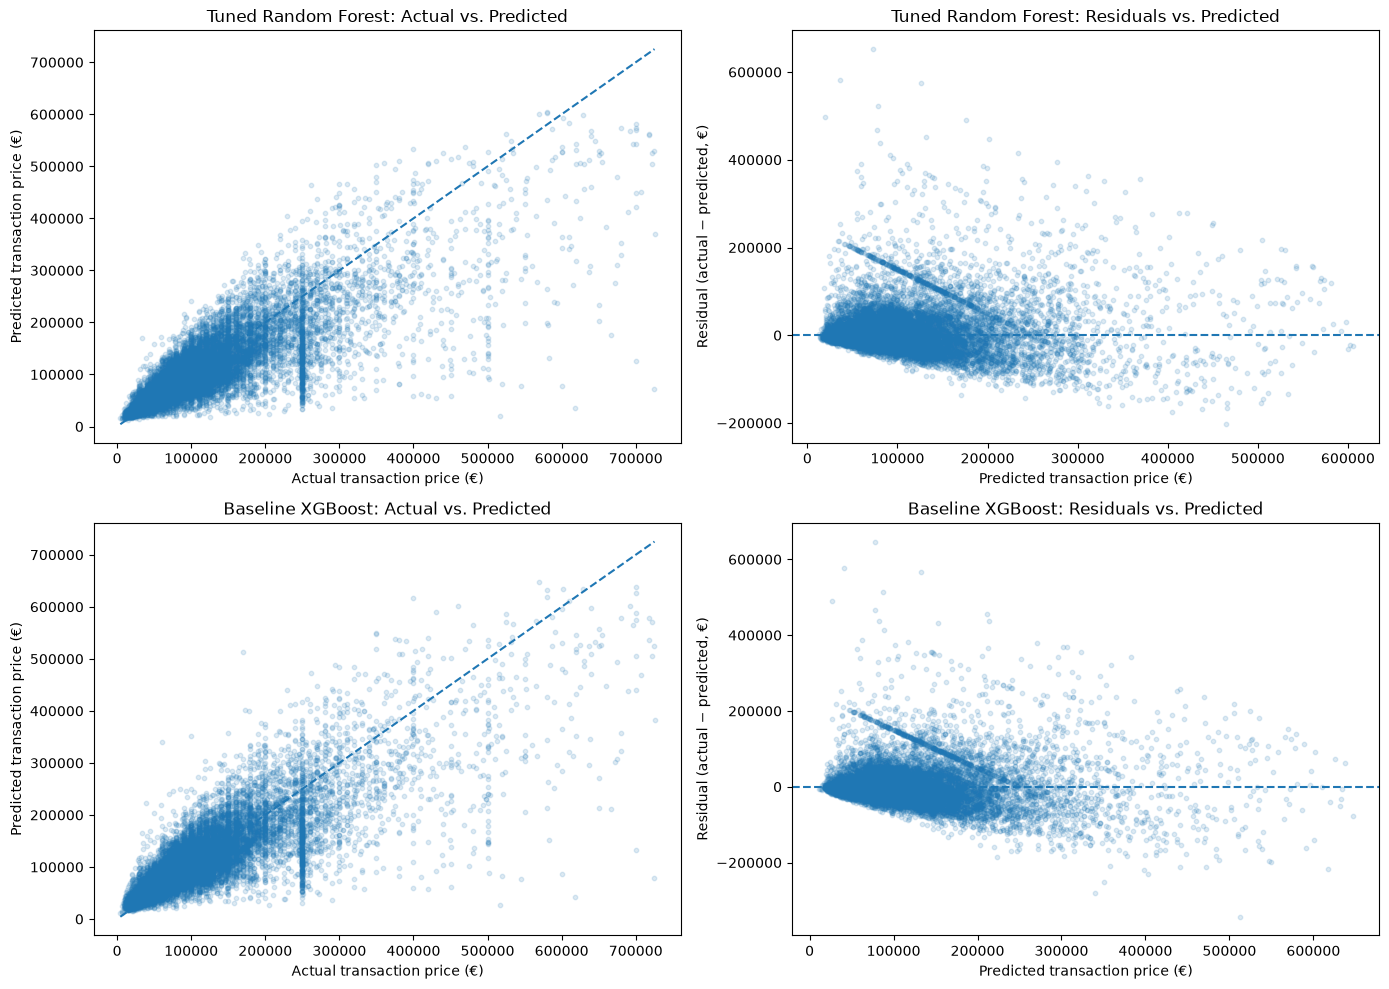

In [97]:

import numpy as np
import matplotlib.pyplot as plt

y_actual = np.asarray(y_test_common)

diagnostic_predictions = {
    "Tuned Random Forest": np.asarray(pred_rf_tuned_p99),
    "Baseline XGBoost": np.asarray(pred_xgb_baseline_p99),
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for row, (model_name, y_pred) in enumerate(diagnostic_predictions.items()):
    residuals = y_actual - y_pred

    # Actual vs. predicted
    ax = axes[row, 0]
    ax.scatter(y_actual, y_pred, alpha=0.15, s=10)
    lower = min(y_actual.min(), y_pred.min())
    upper = max(y_actual.max(), y_pred.max())
    ax.plot([lower, upper], [lower, upper], linestyle="--")
    ax.set_title(f"{model_name}: Actual vs. Predicted")
    ax.set_xlabel("Actual transaction price (€)")
    ax.set_ylabel("Predicted transaction price (€)")

    # Residuals vs. predicted
    ax = axes[row, 1]
    ax.scatter(y_pred, residuals, alpha=0.15, s=10)
    ax.axhline(0, linestyle="--")
    ax.set_title(f"{model_name}: Residuals vs. Predicted")
    ax.set_xlabel("Predicted transaction price (€)")
    ax.set_ylabel("Residual (actual − predicted, €)")

plt.tight_layout()
plt.show()


### Distribution of Residuals

To complement the scatter plots, we examine the distribution of residuals for the Tuned Random Forest and Baseline XGBoost models.

The histograms help us assess whether prediction errors are centered around zero, whether they are skewed toward underprediction or overprediction, and whether large errors occur in the tails of the distribution.

Residuals do not need to follow a normal distribution for these nonlinear models. Here, the histograms are used to describe and compare their error distributions rather than to test a linear regression assumption.

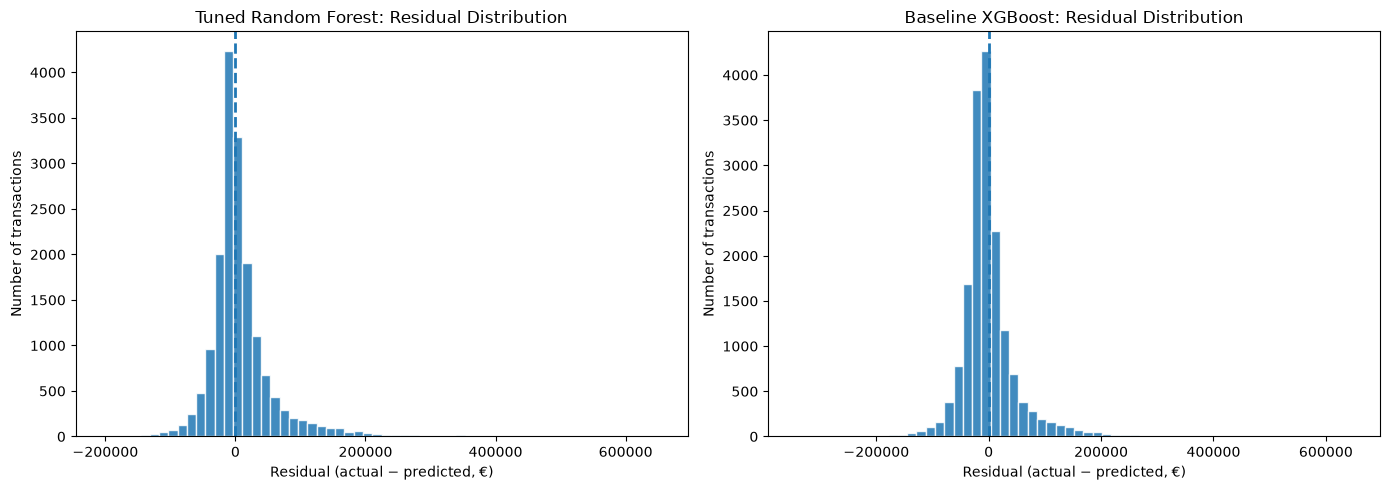

In [100]:

import matplotlib.pyplot as plt
import numpy as np

y_actual = np.asarray(y_test_common)

diagnostic_predictions = {
    "Tuned Random Forest": np.asarray(pred_rf_tuned_p99),
    "Baseline XGBoost": np.asarray(pred_xgb_baseline_p99),
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (model_name, y_pred) in zip(
    axes, diagnostic_predictions.items()
):
    residuals = y_actual - y_pred

    ax.hist(residuals, bins=60, edgecolor="white", alpha=0.85)
    ax.axvline(0, linestyle="--", linewidth=2)
    ax.set_title(f"{model_name}: Residual Distribution")
    ax.set_xlabel("Residual (actual − predicted, €)")
    ax.set_ylabel("Number of transactions")

plt.tight_layout()
plt.show()


### Residual Analysis: Key Findings

**Actual vs. predicted prices.** Both models show a tendency to underpredict some higher-value transactions. Predictions become less accurate as actual transaction prices increase, suggesting that the available features do not fully capture the factors associated with the most expensive properties.

**Residuals vs. predicted prices.** The residual plots indicate that prediction errors vary across the predicted-price range rather than remaining uniformly distributed around zero. This suggests heteroscedasticity.

**Distribution of residuals.** Both models show a concentration of residuals around zero and a long positive tail. Positive residuals represent underpredictions, so the tail indicates that some actual transaction prices substantially exceed their predicted values. These larger errors are consistent with the underprediction observed for higher-value properties.

**Comparison of the models.** The two models exhibit broadly similar residual patterns, including underprediction for some expensive transactions. Although their diagnostic plots appear similar, their predictive performance is not identical: the Tuned Random Forest achieves lower MAE, while Baseline XGBoost achieves lower RMSE and slightly higher (R^2) on the held-out test set.

All in all, residual analysis reveals limitations that aggregate metrics alone cannot fully describe. Both models capture useful patterns in transaction prices, but their errors are not uniform across the price range, and high-value transactions remain challenging to predict. These findings should be considered when interpreting the models' performance and potential practical applications.